In [ ]:
!pip install kaggle

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"brockmr","key":"86c8112501dcf4db02068b062fed5c19"}'}

In [ ]:
!kaggle datasets download -d brjapon/cwru-bearing-datasets
!unzip cwru-bearing-datasets.zip

Dataset URL: https://www.kaggle.com/datasets/brjapon/cwru-bearing-datasets
License(s): CC-BY-SA-4.0
100% 40.4M/40.4M [00:00<00:00, 79.3MB/s]

Archive:  cwru-bearing-datasets.zip
  inflating: CWRU_48k_load_1_CNN_data.npz  
  inflating: feature_time_48k_2048_load_1.csv  
  inflating: raw/B007_1_123.mat      
  inflating: raw/B014_1_190.mat      
  inflating: raw/B021_1_227.mat      
  inflating: raw/IR007_1_110.mat     
  inflating: raw/IR014_1_175.mat     
  inflating: raw/IR021_1_214.mat     
  inflating: raw/OR007_6_1_136.mat   
  inflating: raw/OR014_6_1_202.mat   
  inflating: raw/OR021_6_1_239.mat   
  inflating: raw/Time_Normal_1_098.mat  


In [ ]:
!kaggle datasets download -d dippatel03/paderborn-db
!unzip paderborn-db.zip

Dataset URL: https://www.kaggle.com/datasets/dippatel03/paderborn-db
License(s): CC0-1.0
100% 9.02G/9.02G [01:36<00:00, 100MB/s] 

Archive:  paderborn-db.zip
  inflating: K001/K001.pdf           
  inflating: K001/N09_M07_F10_K001_1.mat  
  inflating: K001/N09_M07_F10_K001_10.mat  
  inflating: K001/N09_M07_F10_K001_11.mat  
  inflating: K001/N09_M07_F10_K001_12.mat  
  inflating: K001/N09_M07_F10_K001_13.mat  
  inflating: K001/N09_M07_F10_K001_14.mat  
  inflating: K001/N09_M07_F10_K001_15.mat  
  inflating: K001/N09_M07_F10_K001_16.mat  
  inflating: K001/N09_M07_F10_K001_17.mat  
  inflating: K001/N09_M07_F10_K001_18.mat  
  inflating: K001/N09_M07_F10_K001_19.mat  
  inflating: K001/N09_M07_F10_K001_2.mat  
  inflating: K001/N09_M07_F10_K001_20.mat  
  inflating: K001/N09_M07_F10_K001_3.mat  
  inflating: K001/N09_M07_F10_K001_4.mat  
  inflating: K001/N09_M07_F10_K001_5.mat  
  inflating: K001/N09_M07_F10_K001_6.mat  
  inflating: K001/N09_M07_F10_K001_7.mat  
  inflating: K001/N

In [ ]:
import os

wav_files = []

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith(".wav"):
            wav_files.append(os.path.join(root, f))

print(len(wav_files))
print(wav_files[:5])

0
[]


In [ ]:
import os

mat_files = []

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith(".mat"):
            mat_files.append(os.path.join(root, f))

print(len(mat_files))
print(mat_files[:5])

2570
['/content/KI01/N15_M07_F10_KI01_18.mat', '/content/KI01/N15_M07_F04_KI01_12.mat', '/content/KI01/N15_M07_F04_KI01_17.mat', '/content/KI01/N15_M01_F10_KI01_7.mat', '/content/KI01/N15_M07_F04_KI01_18.mat']


In [ ]:
import scipy.io

file = mat_files[0]

data = scipy.io.loadmat(file)

print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'N15_M07_F10_KI01_18'])


In [ ]:
import numpy as np

for k in data.keys():
    if k.startswith("__"):
        continue

    arr = data[k]

    if isinstance(arr, np.ndarray):
        signal = arr.flatten()
        print("using", k, signal.shape)
        break

using N15_M07_F10_KI01_18 (1,)


In [ ]:
import scipy.io

file = mat_files[0]

data = scipy.io.loadmat(file)

for k in data.keys():
    print(k, type(data[k]))

__header__ <class 'bytes'>
__version__ <class 'str'>
__globals__ <class 'list'>
N15_M07_F10_KI01_18 <class 'numpy.ndarray'>


In [ ]:
import numpy as np

for k in data.keys():
    if k.startswith("__"):
        continue

    arr = data[k]

    print("shape:", arr.shape)

    signal = arr[0][0][2][0][6][2]   # Paderborn structure

    signal = signal.astype(float)

    print(signal.shape)
    break

shape: (1, 1)
(1, 256084)


In [ ]:
import scipy.io

file = mat_files[0]

data = scipy.io.loadmat(file)

for k in data.keys():
    if not k.startswith("__"):
        print(k)
        print(type(data[k]))
        print(data[k].shape)

N15_M07_F10_KI01_18
<class 'numpy.ndarray'>
(1, 1)


In [ ]:
key = [k for k in data.keys() if not k.startswith("__")][0]

struct = data[key]

# correct nested extraction
signal = struct[0][0][2][0][6][2]

signal = signal.astype(float).flatten()

print(signal.shape)

(256084,)


In [ ]:
print(type(signal))
print(signal[:10])

<class 'numpy.ndarray'>
[ 1.3092041   0.72631836  1.06201172 -0.03662109 -0.44555664 -1.39160156
 -0.86669922  0.07019043  2.10876465  1.35192871]


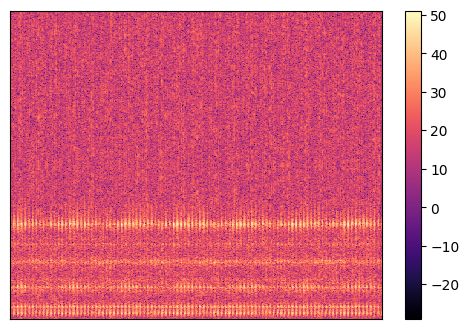

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

S = librosa.stft(signal)

S_db = librosa.amplitude_to_db(np.abs(S))

plt.figure(figsize=(6,4))
librosa.display.specshow(S_db, sr=64000)
plt.colorbar()
plt.show()

In [ ]:
import os

spec_dir = "/content/spec_dataset"

os.makedirs(spec_dir, exist_ok=True)

In [ ]:
import scipy.io
import numpy as np

def get_signal(file):

    data = scipy.io.loadmat(file)

    key = [k for k in data.keys() if not k.startswith("__")][0]

    struct = data[key]

    signal = struct[0][0][2][0][6][2]

    signal = signal.astype(float).flatten()

    return signal

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt


def make_spec(file, i):

    try:

        signal = get_signal(file)

        S = librosa.stft(signal)

        S_db = librosa.amplitude_to_db(abs(S))

        plt.figure(figsize=(3,3))

        librosa.display.specshow(S_db)

        plt.axis("off")

        plt.savefig(
            f"/content/spec_dataset/{i}.png",
            bbox_inches="tight",
            pad_inches=0
        )

        plt.close()

    except:
        pass

In [ ]:
import os

mat_files = []

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith(".mat"):
            mat_files.append(os.path.join(root, f))

print(len(mat_files))

2570


0
20
40
60
80
100
120
140
160
180
DONE


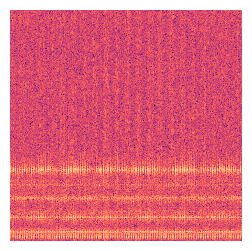

In [ ]:
for i, f in enumerate(mat_files[:200]):   # start with 200

    make_spec(f, i)

    if i % 20 == 0:
        print(i)

print("DONE")

In [ ]:
os.listdir("/content/spec_dataset")[:10]

['16.png',
 '126.png',
 '147.png',
 '109.png',
 '139.png',
 '9.png',
 '131.png',
 '45.png',
 '46.png',
 '68.png']

In [ ]:
import os

base = "/content/cnn_dataset"

classes = ["normal", "inner", "outer", "ball"]

for c in classes:
    os.makedirs(f"{base}/{c}", exist_ok=True)

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import os


def make_spec(file, i):

    try:

        signal = get_signal(file)

        S = librosa.stft(signal)
        S_db = librosa.amplitude_to_db(abs(S))

        name = os.path.basename(file)

        if "K0" in file:
            cls = "normal"
        elif "KI" in file:
            cls = "inner"
        elif "KA" in file:
            cls = "outer"
        elif "KB" in file:
            cls = "ball"
        else:
            return

        save_path = f"/content/cnn_dataset/{cls}/{i}.png"

        plt.figure(figsize=(3,3))
        librosa.display.specshow(S_db)
        plt.axis("off")

        plt.savefig(save_path,
                    bbox_inches="tight",
                    pad_inches=0)

        plt.close()

    except:
        pass

In [ ]:
for i, f in enumerate(mat_files[:400]):

    make_spec(f, i)

    if i % 20 == 0:
        print(i)

0
20
40
60
80
100
120
140
160
180
200
220
240
260
280
300
320
340
360
380


In [ ]:
for c in ["normal","inner","outer","ball"]:
    print(c, len(os.listdir(f"/content/cnn_dataset/{c}")))

normal 80
inner 160
outer 150
ball 0


In [ ]:
!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
data_dir = "/content/cnn_dataset"

img_size = (128,128)
batch_size = 16

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

Found 390 files belonging to 4 classes.
Using 312 files for training.
Found 390 files belonging to 4 classes.
Using 78 files for validation.


In [ ]:
normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

In [ ]:
model = keras.Sequential([

    layers.Conv2D(16, 3, activation="relu", input_shape=(128,128,3)),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),

    layers.Dense(4, activation="softmax")
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 334ms/step - accuracy: 0.4936 - loss: 0.9781 - val_accuracy: 0.6154 - val_loss: 0.7272
Epoch 2/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 253ms/step - accuracy: 0.6538 - loss: 0.6838 - val_accuracy: 0.8333 - val_loss: 0.4750
Epoch 3/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 331ms/step - accuracy: 0.7147 - loss: 0.4939 - val_accuracy: 0.7821 - val_loss: 0.5233
Epoch 4/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 241ms/step - accuracy: 0.7853 - loss: 0.4100 - val_accuracy: 0.7821 - val_loss: 0.4910
Epoch 5/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 317ms/step - accuracy: 0.7724 - loss: 0.4600 - val_accuracy: 0.7821 - val_loss: 0.3288


In [ ]:
model.save("/content/fault_model.h5")

In [ ]:
import cv2
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import scipy.io

In [ ]:
def get_signal(file):

    data = scipy.io.loadmat(file)

    key = [k for k in data.keys() if not k.startswith("__")][0]

    struct = data[key]

    signal = struct[0][0][2][0][6][2]

    signal = signal.astype(float).flatten()

    return signal

In [ ]:
def make_spec_image(file):

    signal = get_signal(file)

    S = librosa.stft(signal)

    S_db = librosa.amplitude_to_db(abs(S))

    plt.figure(figsize=(3,3))
    librosa.display.specshow(S_db)
    plt.axis("off")

    plt.savefig("/content/test.png",
                bbox_inches="tight",
                pad_inches=0)

    plt.close()

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/fault_model.h5")

In [ ]:
test_file = mat_files[10]

make_spec_image(test_file)

img = cv2.imread("/content/test.png")

img = cv2.resize(img, (128,128))

img = img / 255.0

img = np.expand_dims(img, axis=0)

pred = model.predict(img)

print(pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
[[1.0175317e-05 3.3143386e-01 1.7759427e-05 6.6853827e-01]]


In [ ]:
classes = ["normal","inner","outer","ball"]

print(classes[np.argmax(pred)])

ball


In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model("/content/fault_model.h5")

converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

open("model.tflite","wb").write(tflite_model)

Saved artifact at '/tmp/tmpufbluitv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  140356688557648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383101136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383101520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383098256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383100944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383099792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383098640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383098832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383100752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383100368: TensorSpec(shape=(), dtype=tf.resource, name=None)


3311624

In [ ]:
from google.colab import files
files.download("model.tflite")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!xxd -i model.tflite > model.h

In [ ]:
files.download("model.h")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import scipy.io
from scipy.fft import fft
import os

In [ ]:
def get_signal(file):

    data = scipy.io.loadmat(file)

    key = [k for k in data.keys() if not k.startswith("__")][0]

    struct = data[key]

    signal = struct[0][0][2][0][6][2]

    signal = signal.astype(float).flatten()

    return signal

In [ ]:
def get_features(signal):

    f = np.abs(fft(signal))

    f = f[:32]   # only 32 values

    return f

In [ ]:
X = []
y = []

for f in mat_files[:500]:

    try:

        sig = get_signal(f)

        feat = get_features(sig)

        if "K0" in f:
            label = 0
        elif "KI" in f:
            label = 1
        elif "KA" in f:
            label = 2
        elif "KB" in f:
            label = 3
        else:
            continue

        X.append(feat)
        y.append(label)

    except:
        pass

X = np.array(X)
y = np.array(y)

print(X.shape, y.shape)

(490, 32) (490,)


In [ ]:
import tensorflow as tf
from tensorflow import keras

model = keras.Sequential([
    keras.Input(shape=(32,)),

    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(16, activation="relu"),

    keras.layers.Dense(4, activation="softmax")
])

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
model.fit(X, y, epochs=20)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.1837 - loss: 751.0268
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1918 - loss: 249.7251 
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3327 - loss: 124.2523 
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4204 - loss: 62.2599  
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3959 - loss: 28.8533 
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3408 - loss: 14.7254
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3755 - loss: 12.3979 
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4041 - loss: 11.4354 
Epoch 9/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3694 - loss: 10.4630
Epoch 10/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3857 - loss: 9.9578  
Epoch 11/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4102 - loss: 9.4709 
Epoch 12/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step -

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

open("model.tflite","wb").write(tflite_model)

Saved artifact at '/tmp/tmpr3qw26cp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32), dtype=tf.float32, name='keras_tensor_100')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  140356383112080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383110736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383110928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383107472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383110160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383110544: TensorSpec(shape=(), dtype=tf.resource, name=None)


5596

In [ ]:
!xxd -i model.tflite > model.h

In [ ]:
files.download("model.h")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model("fault_model.h5")

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

open("model.tflite","wb").write(tflite_model)

Saved artifact at '/tmp/tmp27sx0hmx'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  140356383103824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383099984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383104016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383109200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383103632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383108624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383109776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383111504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383109008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356383112272: TensorSpec(shape=(), dtype=tf.resource, name=None)


835952

In [ ]:
import os
os.path.getsize("model.tflite")

835952

In [ ]:
import tensorflow as tf
from tensorflow import keras

model = keras.Sequential([
    keras.Input(shape=(16,)),

    keras.layers.Dense(8, activation="relu"),

    keras.layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(X[:, :16], y, epochs=20)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.3265 - loss: 1445.9779
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3265 - loss: 1155.5125
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3265 - loss: 891.5587  
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3429 - loss: 646.6644 
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3878 - loss: 485.6364 
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3510 - loss: 422.5551 
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3796 - loss: 366.4978 
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3306 - loss: 322.5201
Epoch 9/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3265 - loss: 280.5111 
Epoch 10/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3265 - loss: 243.5412 
Epoch 11/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3306 - loss: 210.0716 
Epoch 12/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

open("model.tflite","wb").write(tflite_model)

Saved artifact at '/tmp/tmpw4cwy0_c'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 16), dtype=tf.float32, name='keras_tensor_149')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  140356379601488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356379605136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356379605328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140356379605904: TensorSpec(shape=(), dtype=tf.resource, name=None)


2432

In [ ]:
import os
os.path.getsize("model.tflite")

2432

In [ ]:
!xxd -i model.tflite > model.h

In [ ]:
files.download("model.h")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>